In [1]:
import os, io, zipfile, urllib.request, re
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay
from nltk.stem import PorterStemmer
from IPython.display import display

# Download the authentic UCI SMS Spam Collection dataset.
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
try:
    raw = urllib.request.urlopen(DATA_URL, timeout=30).read()
    archive = zipfile.ZipFile(io.BytesIO(raw))
    name = next(n for n in archive.namelist() if n.endswith('SMSSpamCollection'))
    dataset_bytes = archive.read(name)
except Exception as error:
    print('Automatic download unavailable:', error)
    print('Download ZIP from https://archive.ics.uci.edu/dataset/228/sms+spam+collection and upload it here.')
    from google.colab import files
    uploaded = files.upload()
    name = next(iter(uploaded))
    if name.lower().endswith('.zip'):
        archive = zipfile.ZipFile(io.BytesIO(uploaded[name]))
        inner = next(n for n in archive.namelist() if n.endswith('SMSSpamCollection'))
        dataset_bytes = archive.read(inner)
    else:
        dataset_bytes = uploaded[name]

df = pd.read_csv(io.BytesIO(dataset_bytes), sep='\t', header=None, names=['label','message'], encoding='utf-8')
df = df[df.label.isin(['ham','spam'])].dropna().reset_index(drop=True)
print('Dataset shape:',df.shape)
print('Class distribution:'); print(df.label.value_counts())
display(df.head(10))


Dataset shape: (5572, 2)
Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


## Train and evaluate all four models

In [2]:
# Preprocess before vectorization. Fit TF-IDF on training data ONLY (no leakage).
stemmer = PorterStemmer()
def preprocess(s):
    tokens = re.findall(r"[a-z]+", str(s).lower())
    return ' '.join(stemmer.stem(t) for t in tokens if t not in ENGLISH_STOP_WORDS)

X_train, X_test, y_train, y_test = train_test_split(
    df.message, df.label, test_size=0.20, random_state=42, stratify=df.label)

models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=20, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5, metric='cosine', algorithm='brute'),
    'SVM': LinearSVC(random_state=42, max_iter=5000),
    'Naive Bayes': MultinomialNB()
}
results=[]; fitted={}; predictions={}
for name, classifier in models.items():
    pipe = Pipeline([('tfidf',TfidfVectorizer(preprocessor=preprocess, lowercase=False, ngram_range=(1,2), min_df=2)), ('classifier',classifier)])
    pipe.fit(X_train, y_train)
    pred=pipe.predict(X_test)
    fitted[name]=pipe;predictions[name]=pred
    precision,recall,f1,_ = precision_recall_fscore_support(y_test,pred,average='binary',pos_label='spam',zero_division=0)
    results.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Precision':precision,'Recall':recall,'F1':f1})
    print('\n',name);print(classification_report(y_test,pred,labels=['ham','spam'],zero_division=0))
metrics=pd.DataFrame(results).sort_values('F1',ascending=False).reset_index(drop=True)
display(metrics)
metrics.to_csv('model_metrics.csv',index=False)



 Decision Tree
              precision    recall  f1-score   support

         ham       0.97      0.98      0.98       966
        spam       0.88      0.80      0.84       149

    accuracy                           0.96      1115
   macro avg       0.92      0.89      0.91      1115
weighted avg       0.96      0.96      0.96      1115


 KNN
              precision    recall  f1-score   support

         ham       0.97      1.00      0.99       966
        spam       1.00      0.82      0.90       149

    accuracy                           0.98      1115
   macro avg       0.99      0.91      0.94      1115
weighted avg       0.98      0.98      0.97      1115


 SVM
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.91      0.93       149

    accuracy                           0.98      1115
   macro avg       0.97      0.95      0.96      1115
weighted avg       0.98      0.98      0.98   

,Model,Accuracy,Precision,Recall,F1
0,SVM,0.982063,0.957447,0.906040,0.931034
1,KNN,0.975785,1.000000,0.818792,0.900369
2,Naive Bayes,0.970404,1.000000,0.778523,0.875472
3,Decision Tree,0.957848,0.875000,0.798658,0.835088


## Model comparison and confusion matrices

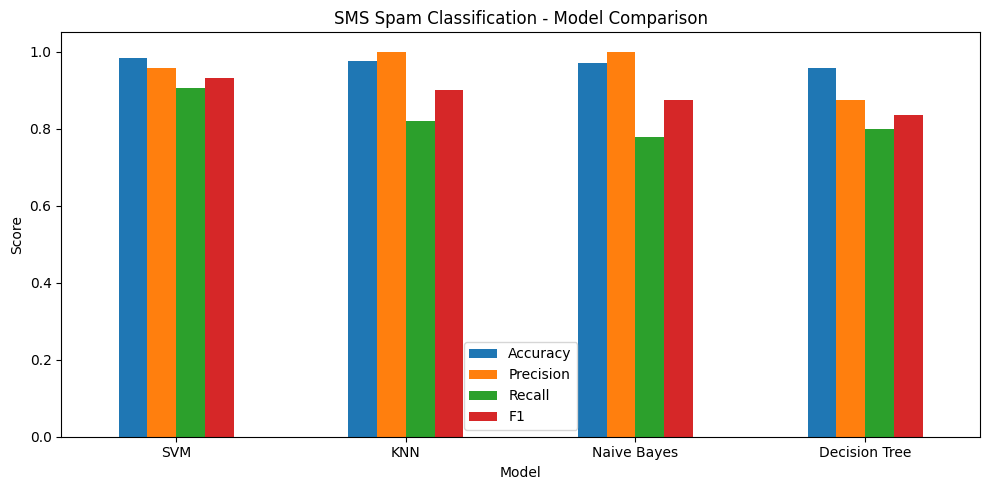

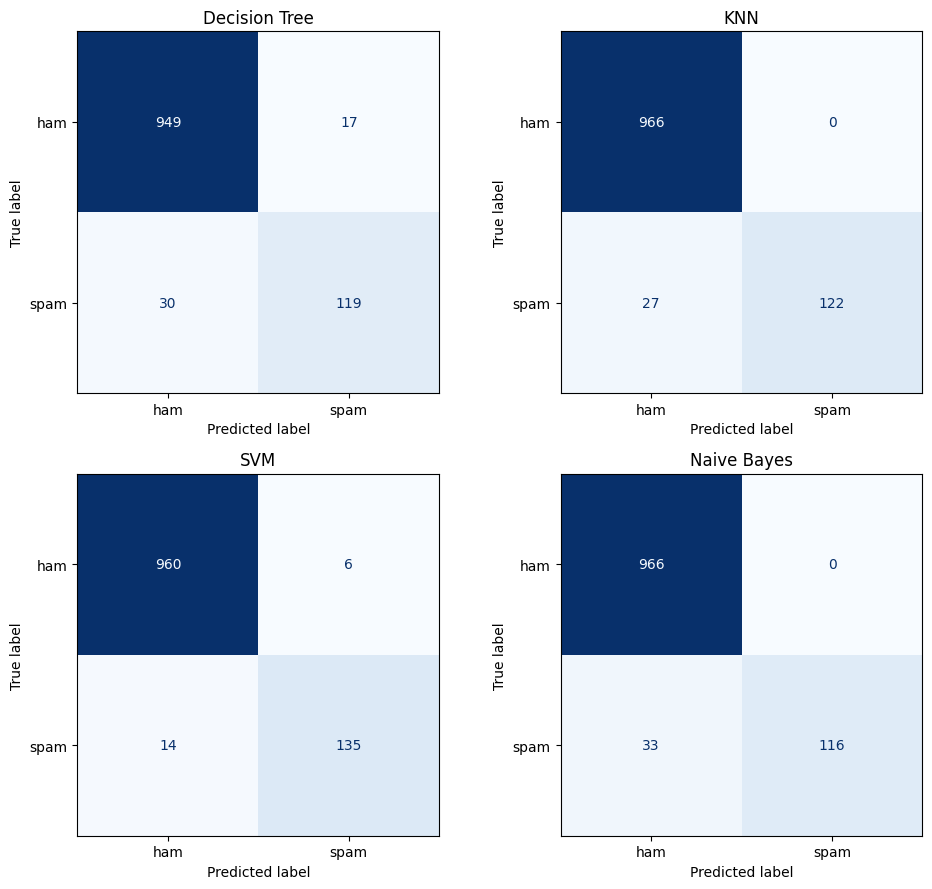

In [3]:
# Comparison chart: same split, same feature extraction, same positive class.
ax=metrics.set_index('Model')[['Accuracy','Precision','Recall','F1']].plot(kind='bar',figsize=(10,5),ylim=(0,1.05),rot=0)
ax.set_title('SMS Spam Classification - Model Comparison')
ax.set_ylabel('Score');plt.tight_layout();plt.savefig('model_comparison.png',dpi=180);plt.show()

fig,axes=plt.subplots(2,2,figsize=(10,9))
for ax,(name,pred) in zip(axes.flat,predictions.items()):
    cm=confusion_matrix(y_test,pred,labels=['ham','spam'])
    ConfusionMatrixDisplay(cm,display_labels=['ham','spam']).plot(ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(name)
plt.tight_layout();plt.savefig('confusion_matrices.png',dpi=180);plt.show()


## What-if experiment and final recommendation

,K,Accuracy,Spam_Precision,Spam_Recall,Spam_F1
0,3,0.958744,0.865248,0.818792,0.841379
1,5,0.975785,1.000000,0.818792,0.900369
2,9,0.970404,0.983333,0.791946,0.877323


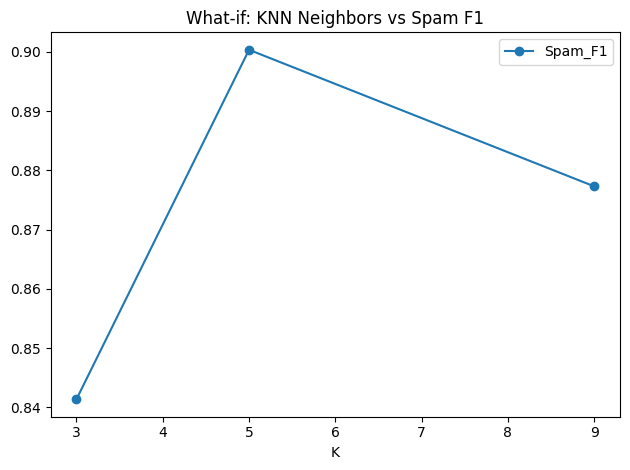

BEST MODEL BY SPAM F1: SVM
Spam F1: 0.931 Accuracy: 0.9821
Recommendation: prioritize spam F1 to balance missed spam and false alarms; inspect confusion matrices.
NOTE: The what-if experiment uses the test set for illustration only; for unbiased parameter tuning use validation or cross-validation.


In [4]:
# What-if experiment: change KNN n_neighbors from 5 to 3 and 9, all else fixed.
whatif=[]
for k in [3,5,9]:
    pipe=Pipeline([('tfidf',TfidfVectorizer(preprocessor=preprocess,lowercase=False,ngram_range=(1,2),min_df=2)),
                   ('classifier',KNeighborsClassifier(n_neighbors=k,metric='cosine',algorithm='brute'))])
    pipe.fit(X_train,y_train); pred=pipe.predict(X_test)
    precision,recall,f1,_=precision_recall_fscore_support(y_test,pred,average='binary',pos_label='spam',zero_division=0)
    whatif.append({'K':k,'Accuracy':accuracy_score(y_test,pred),'Spam_Precision':precision,'Spam_Recall':recall,'Spam_F1':f1})
whatif=pd.DataFrame(whatif)
display(whatif);whatif.to_csv('knn_what_if.csv',index=False)
whatif.plot(x='K',y='Spam_F1',marker='o',title='What-if: KNN Neighbors vs Spam F1');plt.tight_layout();plt.savefig('what_if.png',dpi=180);plt.show()

winner=metrics.iloc[0]
print('BEST MODEL BY SPAM F1:',winner.Model)
print('Spam F1:',round(float(winner.F1),4),'Accuracy:',round(float(winner.Accuracy),4))
print('Recommendation: prioritize spam F1 to balance missed spam and false alarms; inspect confusion matrices.')
print('NOTE: The what-if experiment uses the test set for illustration only; for unbiased parameter tuning use validation or cross-validation.')
